In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import os
from scipy.signal import butter, filtfilt
from scipy.stats import mode, skew, kurtosis
import pickle
import matplotlib.patches as mpatches
from scipy.signal import find_peaks
from sklearn.model_selection import LeaveOneGroupOut
from scipy.signal import welch

base_path = "/kaggle/input/datasets/protobioengineering/wearable-device-dataset-during-stress-and-exercise/wearable-device-dataset-from-induced-stress-and-structured-exercise-sessions-1.0.1/Wearable_Dataset/STRESS"
subjects = ["f01","f02","f03","f04","f05","f06","f08","f09","f10","f11","f12","f13","f15","f16","f17","f18"]

In [2]:
for subject in subjects:
    tags_path = f"{base_path}/{subject}/tags.csv"
    try:
        tags_df = pd.read_csv(tags_path, header=None)
        print(f"{subject}: {len(tags_df)} tags")
    except:
        print(f"{subject}: erro")

f01: 9 tags
f02: 9 tags
f03: 9 tags
f04: 9 tags
f05: 9 tags
f06: 9 tags
f08: 9 tags
f09: 9 tags
f10: 9 tags
f11: 9 tags
f12: 9 tags
f13: 9 tags
f15: 9 tags
f16: 9 tags
f17: 9 tags
f18: 9 tags


In [3]:
import pandas as pd

info_path = "/kaggle/input/datasets/protobioengineering/wearable-device-dataset-during-stress-and-exercise/wearable-device-dataset-from-induced-stress-and-structured-exercise-sessions-1.0.1/subject-info.csv"
df_info = pd.read_csv(info_path)
print(df_info.columns.tolist())
print(df_info.iloc[:, 0].tolist())  # ver todos os IDs
print(df_info.shape)

['Info ', 'Gender', 'Age', 'Height (cm)', 'Weight (kg)', 'Does physical activity regularly?', 'Protocol', 'Stress Inducement', 'Aerobic Exercise', 'Anaerobic Exercise']
['S01', 'S02', 'S03', 'S04', 'S05', 'S06', 'S07', 'S08', 'S09', 'S10', 'S11', 'S12', 'S13', 'S14', 'S15', 'S16', 'S17', 'S18', 'f01', 'f02', 'f03', 'f04', 'f05', 'f06', 'f07', 'f08', 'f09', 'f10', 'f11', 'f12', 'f13', 'f14', 'f15', 'f16', 'f17', 'f18', nan, 'References:', 'm:male', 'f: female', 'V1: First version of the protocol', 'V2: Second version of the protocol', '* Wrong wristband placement.', '** Connection Loss ', '*** Protocol was not fully completed', '**** Files with Annotations']
(46, 10)


In [4]:
def parse_e4(df):
    timestamp_start = df.iloc[0, 0]
    fs              = df.iloc[1, 0]
    signal          = df.iloc[2:, 0].reset_index(drop=True)
    return timestamp_start, fs, signal

In [5]:
def bandpass_filter(signal, lowcut, highcut, fs, order=4):
    nyq = fs / 2
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype='band')
    if len(signal) < 30:
        return signal
    return filtfilt(b, a, signal, method='gust')

In [6]:
def lowpass_filter(signal, cutoff, fs, order=4):
    nyq = fs / 2
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low')
    if len(signal) < 20:
        return signal  # sinal demasiado curto, devolve sem filtrar
    return filtfilt(b, a, signal, method='gust')

In [7]:
def preprocess_acc(data_acc_wrist, data_acc_chest=None):
    
    # --- Wrist (E4) - 32 Hz ---
    fs_wrist = 32
    xw = data_acc_wrist[:, 0]
    yw = data_acc_wrist[:, 1]
    zw = data_acc_wrist[:, 2]
    xw_f = bandpass_filter(xw, lowcut=0.5, highcut=10, fs=fs_wrist)
    yw_f = bandpass_filter(yw, lowcut=0.5, highcut=10, fs=fs_wrist)
    zw_f = bandpass_filter(zw, lowcut=0.5, highcut=10, fs=fs_wrist)
    magnitude_wrist = np.sqrt(xw_f**2 + yw_f**2 + zw_f**2)

    # --- Chest (RespiBAN) - 70 Hz --- só se existir
    if data_acc_chest is None:
        return magnitude_wrist, None

    fs_chest = 70
    xc = data_acc_chest[:, 0]
    yc = data_acc_chest[:, 1]
    zc = data_acc_chest[:, 2]
    xc_f = bandpass_filter(xc, lowcut=0.5, highcut=10, fs=fs_chest)
    yc_f = bandpass_filter(yc, lowcut=0.5, highcut=10, fs=fs_chest)
    zc_f = bandpass_filter(zc, lowcut=0.5, highcut=10, fs=fs_chest)
    magnitude_chest = np.sqrt(xc_f**2 + yc_f**2 + zc_f**2)

    return magnitude_wrist, magnitude_chest

In [8]:
def preprocess_eda(data_eda_wrist, data_eda_chest):
    
    # Wrist (E4) @ 4 Hz — só passa-baixa, nyquist é apenas 2 Hz
    eda_wrist_filtered = lowpass_filter(data_eda_wrist, cutoff=1, fs=4)

    if data_eda_chest is None:
        return eda_wrist_filtered, None
    
    # Chest (RespiBAN) @ 70 Hz — bandpass funciona bem
    eda_chest_filtered = lowpass_filter(data_eda_chest, cutoff=1, fs=70)

    return eda_wrist_filtered, eda_chest_filtered

In [9]:
def preprocess_temp(data_temp_wrist):
    
    # Wrist (E4) @ 4 Hz
    temp_wrist_filtered = lowpass_filter(data_temp_wrist, cutoff=0.1, fs=4)

    return temp_wrist_filtered

In [10]:
def preprocess_bvp(data_bvp_wrist, fs=64):
    
    data_bvp_wrist = np.array(data_bvp_wrist).flatten()
    bvp_filtered = bandpass_filter(data_bvp_wrist, lowcut=0.5, highcut=4, fs=fs)
    
    window = int(fs * 0.1)
    bvp_smooth = np.convolve(bvp_filtered, np.ones(window)/window, mode='same')
    
    threshold = np.mean(bvp_smooth) + np.std(bvp_smooth)
    picos, _ = find_peaks(bvp_smooth, distance=40, height=threshold, prominence=np.std(bvp_smooth))
    
    ibi_samples = np.diff(picos)
    ibi_seconds = ibi_samples / fs
    
    mask = (ibi_seconds > 0.4) & (ibi_seconds < 1.5)
    ibi_clean = ibi_seconds[mask]
    picos_clean = picos[1:][mask]
    
    if len(ibi_clean) < 2:
        duracao = len(data_bvp_wrist) // fs
        return np.full(duracao, 75.0), np.full(duracao, 0.8)
    
    hr = np.clip(60 / ibi_clean, 40, 150)
    hr_smooth = np.convolve(hr, np.ones(5)/5, mode='same')
    ibi_smooth = np.convolve(ibi_clean, np.ones(5)/5, mode='same')
    
    tempo_picos = picos_clean / fs
    duracao = len(data_bvp_wrist) / fs
    tempo_uniforme = np.arange(0, duracao, 1)
    
    hr_1hz  = np.interp(tempo_uniforme, tempo_picos, hr_smooth)
    ibi_1hz = np.interp(tempo_uniforme, tempo_picos, ibi_smooth)
    
    return hr_1hz, ibi_1hz

In [11]:
def windowed_energy(magnitude, fs, window_sec=1):
    window_size = fs * window_sec
    n_windows = len(magnitude) // window_size
    energy = []
    for i in range(n_windows):
        window = magnitude[i*window_size : (i+1)*window_size]
        energy.append(np.mean(window**2))
    return np.array(energy)

In [12]:
def windowed_hrv(ibi_1hz, window_sec=30, step_sec=1):
    rmssd_list = []
    sdnn_list  = []
    
    for i in range(0, len(ibi_1hz) - window_sec, step_sec):
        window = ibi_1hz[i : i + window_sec]
        
        # SDNN
        sdnn = np.std(window)
        
        # RMSSD
        diffs = np.diff(window)
        rmssd = np.sqrt(np.mean(diffs**2))
        
        rmssd_list.append(rmssd)
        sdnn_list.append(sdnn)
    
    return np.array(rmssd_list), np.array(sdnn_list)

In [13]:
def downsample_labels(labels, fs_labels=700, window_sec=1):
    window_size = fs_labels * window_sec
    n_windows = len(labels) // window_size
    labels_downsampled = []
    for i in range(n_windows):
        window = labels[i*window_size : (i+1)*window_size]
        result = mode(window).mode
        label = result[0] if hasattr(result, '__len__') else result
        labels_downsampled.append(label)
    return np.array(labels_downsampled)

In [14]:
def load_labels_from_tags(base_path, subject, tmct_only=False):
    tags_path = f"{base_path}/{subject}/tags.csv"
    try:
        tags_df = pd.read_csv(tags_path, header=None)
    except pd.errors.EmptyDataError:
        return np.array([])
    
    if len(tags_df) < 2:
        return np.array([])

    timestamps = pd.to_datetime(tags_df[0])
    
    # v2: Baseline, TMCT, First Rest, Real Opinion, Opposite Opinion, Second Rest, Subtract, end
    if tmct_only:
        # 0=baseline, 1=TMCT, -1=tudo o resto (vai ser filtrado)
        block_labels = [0, 1, -1, -1, -1, -1, -1, -1]
    else:
        block_labels = [0, 1, 0, 1, 1, 0, 1, 0]
    
    t_start = timestamps.iloc[0]
    t_end   = timestamps.iloc[-1]
    total_seconds = int((t_end - t_start).total_seconds()) + 1
    
    labels = np.full(total_seconds, -1, dtype=int)
    
    for i in range(len(timestamps) - 1):
        t0 = timestamps.iloc[i]
        t1 = timestamps.iloc[i + 1]
        start_sec = int((t0 - t_start).total_seconds())
        end_sec   = int((t1 - t_start).total_seconds())
        labels[start_sec:end_sec] = block_labels[i]
    
    mask = labels != -1
    return labels[mask]

In [15]:
def load_all_acc(base_path, subjects, tmct_only):
    results = {}
    
    for subject in subjects:
        acc_path = f"{base_path}/{subject}/ACC.csv"
        acc_df = pd.read_csv(acc_path, header=None)
        
        fs_acc = float(acc_df.iloc[1, 0])  # 32 Hz
        data_acc_wrist = acc_df.iloc[2:].values.astype(float)  # 3 colunas x, y, z
        
        magnitude_wrist, _ = preprocess_acc(data_acc_wrist, None)
        
        energy_wrist = windowed_energy(magnitude_wrist, fs=32)
        
        labels_1hz = load_labels_from_tags(base_path, subject, tmct_only)
        
        n = min(len(energy_wrist), len(labels_1hz))
        
        results[subject] = {
            'energy_wrist': energy_wrist[:n],
            'energy_chest': None,  # não existe
            'labels':       labels_1hz[:n]
        }
        
        print(f"ACC: {subject} — {n} segundos processados")
    
    return results

In [16]:
def load_all_eda(base_path, subjects, tmct_only):
    results = {}
    for subject in subjects:
        eda_path = f"{base_path}/{subject}/EDA.csv"
        eda_df = pd.read_csv(eda_path, header=None)
        data_eda_wrist = eda_df.iloc[2:].values.astype(float).flatten()
        
        eda_wrist, _ = preprocess_eda(data_eda_wrist, None)
        energy_wrist = windowed_energy(eda_wrist, fs=4)
        
        labels_1hz = load_labels_from_tags(base_path, subject, tmct_only)
        n = min(len(energy_wrist), len(labels_1hz))
        
        results[subject] = {
            'energy_wrist': energy_wrist[:n],
            'labels':       labels_1hz[:n]
        }
    return results

In [17]:
def load_all_temp(base_path, subjects, tmct_only):
    results = {}
    for subject in subjects:
        temp_df = pd.read_csv(f"{base_path}/{subject}/TEMP.csv", header=None)
        data_temp_wrist = temp_df.iloc[2:].values.astype(float).flatten()
        
        temp_wrist = preprocess_temp(data_temp_wrist)
        energy_wrist = windowed_energy(temp_wrist, fs=4)
        
        labels_1hz = load_labels_from_tags(base_path, subject, tmct_only)
        n = min(len(energy_wrist), len(labels_1hz))
        
        results[subject] = {
            'energy_wrist': energy_wrist[:n],
            'labels':       labels_1hz[:n]
        }
    return results

In [18]:
def load_all_bvp(base_path, subjects, tmct_only):
    results = {}
    
    for subject in subjects:
        bvp_df = pd.read_csv(f"{base_path}/{subject}/BVP.csv", header=None)
        data_bvp_wrist = bvp_df.iloc[2:].values.astype(float).flatten()
        
        hr_wrist, ibi_wrist = preprocess_bvp(data_bvp_wrist, fs=64)
        rmssd, sdnn = windowed_hrv(ibi_wrist, window_sec=30)
        
        labels_1hz = load_labels_from_tags(base_path, subject, tmct_only)
        
        n = min(len(hr_wrist), len(rmssd), len(labels_1hz))
        
        results[subject] = {
            'hr':     hr_wrist[:n],
            'ibi':    ibi_wrist[:n],
            'rmssd':  rmssd[:n],
            'sdnn':   sdnn[:n],
            'labels': labels_1hz[:n]
        }
        
        print(f"BVP: {subject} — {n} segundos processados")
    
    return results

In [19]:
## Pre-Processing

#Load signals (ACC, BVP, EDA, HR, IBI, TEMP)
acc_all = load_all_acc(base_path, subjects, tmct_only=True);
eda_all=load_all_eda(base_path, subjects, tmct_only=True);
temp_all=load_all_temp(base_path, subjects, tmct_only=True);
bvp_all=load_all_bvp(base_path, subjects, tmct_only=True);

ACC: f01 — 573 segundos processados
ACC: f02 — 457 segundos processados
ACC: f03 — 425 segundos processados
ACC: f04 — 367 segundos processados
ACC: f05 — 341 segundos processados
ACC: f06 — 327 segundos processados
ACC: f08 — 387 segundos processados
ACC: f09 — 365 segundos processados
ACC: f10 — 364 segundos processados
ACC: f11 — 404 segundos processados
ACC: f12 — 342 segundos processados
ACC: f13 — 323 segundos processados
ACC: f15 — 351 segundos processados
ACC: f16 — 325 segundos processados
ACC: f17 — 402 segundos processados
ACC: f18 — 322 segundos processados
BVP: f01 — 573 segundos processados
BVP: f02 — 457 segundos processados
BVP: f03 — 425 segundos processados
BVP: f04 — 367 segundos processados
BVP: f05 — 341 segundos processados
BVP: f06 — 327 segundos processados
BVP: f08 — 387 segundos processados
BVP: f09 — 365 segundos processados
BVP: f10 — 364 segundos processados
BVP: f11 — 404 segundos processados
BVP: f12 — 342 segundos processados
BVP: f13 — 323 segundos proc

Total segundos: 573
Rest (0): 121
Stress (1): 452


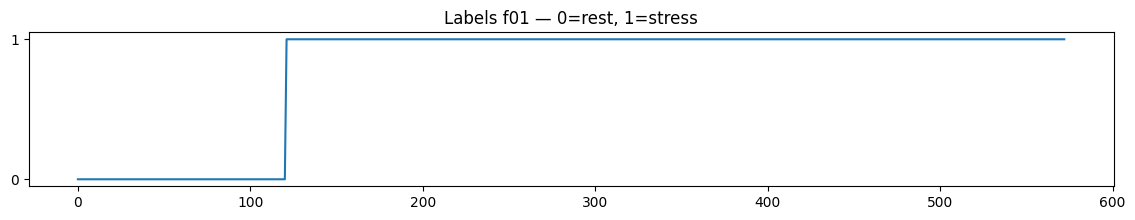

In [20]:
subject = 'f01'
labels = acc_all[subject]['labels']
print(f"Total segundos: {len(labels)}")
print(f"Rest (0): {np.sum(labels==0)}")
print(f"Stress (1): {np.sum(labels==1)}")

plt.figure(figsize=(14,2))
plt.plot(labels)
plt.title(f'Labels f01 — 0=rest, 1=stress')
plt.yticks([0,1])
plt.show()

In [21]:
def plot_signal_energy(energy_wrist, energy_chest, labels, signal_name, subject):
    
    COLORS = {
        0: "#b3d9ff",  # rest
        1: "#ff9999",  # stress
    }
    LABEL_NAMES = {
        0: "Rest",
        1: "Stress"
    }
    
    fig, ax1 = plt.subplots(1, 1, figsize=(14, 3))
    axes     = [ax1]
    energies = [energy_wrist]
    titles   = ["Wrist (E4)"]
    ax_last  = ax1
    
    fig.suptitle(f"{signal_name} Energy com Labels — {subject}")

    for ax, energy, title in zip(axes, energies, titles):
        for i, label in enumerate(labels):
            color = COLORS.get(label, "#dddddd")
            ax.axvspan(i, i+1, color=color, alpha=0.4)
        ax.plot(energy, color="black", linewidth=0.8)
        ax.set_ylabel(f"Energia {signal_name}")
        ax.set_title(title)

    ax_last.set_xlabel("Tempo (s)")
    patches = [mpatches.Patch(color=COLORS[k], label=LABEL_NAMES[k]) for k in COLORS]
    fig.legend(handles=patches, loc="upper right")
    plt.tight_layout()
    plt.show()

In [22]:
def plot_bvp(hr, ibi, labels, subject="S9"):
    
    COLORS = {
        0: "#b3d9ff",  # rest
        1: "#ff9999",  # stress
    }
    LABEL_NAMES = {
        0: "Rest",
        1: "Stress"
    }
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
    fig.suptitle(f"BVP (HR & IBI) com Labels — {subject}")

    for ax, signal, title, ylabel in zip(
        [ax1, ax2],
        [hr, ibi],
        ["Heart Rate", "IBI"],
        ["HR (bpm)", "IBI (s)"]
    ):
        for i, label in enumerate(labels):
            color = COLORS.get(label, "#dddddd")
            ax.axvspan(i, i+1, color=color, alpha=0.4)
        ax.plot(signal, color="black", linewidth=0.8)
        ax.set_ylabel(ylabel)
        ax.set_title(title)

    ax2.set_xlabel("Tempo (s)")
    patches = [mpatches.Patch(color=COLORS[k], label=LABEL_NAMES[k]) for k in COLORS]
    fig.legend(handles=patches, loc="upper right")
    plt.tight_layout()
    plt.show()

In [23]:
acc_all  = load_all_acc(base_path, subjects, tmct_only=True)
eda_all  = load_all_eda(base_path, subjects, tmct_only=True)
temp_all = load_all_temp(base_path, subjects, tmct_only=True)
bvp_all  = load_all_bvp(base_path, subjects, tmct_only=True)

ACC: f01 — 573 segundos processados
ACC: f02 — 457 segundos processados
ACC: f03 — 425 segundos processados
ACC: f04 — 367 segundos processados
ACC: f05 — 341 segundos processados
ACC: f06 — 327 segundos processados
ACC: f08 — 387 segundos processados
ACC: f09 — 365 segundos processados
ACC: f10 — 364 segundos processados
ACC: f11 — 404 segundos processados
ACC: f12 — 342 segundos processados
ACC: f13 — 323 segundos processados
ACC: f15 — 351 segundos processados
ACC: f16 — 325 segundos processados
ACC: f17 — 402 segundos processados
ACC: f18 — 322 segundos processados
BVP: f01 — 573 segundos processados
BVP: f02 — 457 segundos processados
BVP: f03 — 425 segundos processados
BVP: f04 — 367 segundos processados
BVP: f05 — 341 segundos processados
BVP: f06 — 327 segundos processados
BVP: f08 — 387 segundos processados
BVP: f09 — 365 segundos processados
BVP: f10 — 364 segundos processados
BVP: f11 — 404 segundos processados
BVP: f12 — 342 segundos processados
BVP: f13 — 323 segundos proc

In [24]:
def parse_subject_info(sub_path, subject):
    info_path = os.path.join(sub_path, 'subject-info.csv')
    df = pd.read_csv(info_path)
    
    # limpar — só linhas com IDs válidos (S ou f seguido de números)
    id_col = df.columns[0]
    df = df[df[id_col].str.match(r'^[Sf]\d+$', na=False)]
    
    row = df[df[id_col].str.strip() == subject.strip()]
    
    if len(row) == 0:
        return {
            'gender': np.nan, 'age': np.nan,
            'height': np.nan, 'weight': np.nan,
            'physical_activity': np.nan
        }
    
    row = row.iloc[0]
    
    def safe_float(val):
        try:
            return float(val)
        except:
            return np.nan
    
    return {
        'gender':            1 if str(row['Gender']).strip() == 'f' else 0,
        'age':               safe_float(row['Age']),
        'height':            safe_float(row['Height (cm)']),
        'weight':            safe_float(row['Weight (kg)']),
        'physical_activity': 1 if str(row['Does physical activity regularly?']).strip() == 'Yes' else 0
    }

In [25]:
def parse_stress_scores(sub_path, subject):
    """
    Lê o stress score auto-reportado por tarefa para um sujeito.
    Retorna features agregadas para usar como metadata.
    """
    #versão do sujeito (f = v1, S = v2)
    if subject.startswith('f'):
        scores_path = os.path.join(os.path.dirname(sub_path), 'Stress_Level_v1.csv')
        subject_id = subject  # f01, f02...
    else:
        scores_path = os.path.join(os.path.dirname(sub_path), 'Stress_Level_v2.csv')
        subject_id = subject  # S01, S02...
    
    df = pd.read_csv(scores_path)
    
    row = df[df.iloc[:, 0] == subject_id]
    if len(row) == 0:
        return {
            'stress_baseline': np.nan,
            'stress_max':      np.nan,
            'stress_mean':     np.nan,
            'stress_delta':    np.nan
        }
    
    row = row.iloc[0]
    
    baseline = row['Baseline']
    stress_tasks = [row['Stroop'], row['TMCT'], row['Real Opinion'], 
                    row['Opposite Opinion'], row['Subtract']]
    
    return {
        'stress_baseline': baseline,
        'stress_max':      np.max(stress_tasks),
        'stress_mean':     np.mean(stress_tasks),
        'stress_delta':    np.mean(stress_tasks) - baseline  # quanto subiu em relação ao baseline
    }

In [26]:
# data for all subjects - questionaires and data such as coffe, exercise...
subject_meta = {}
sub_path="/kaggle/input/datasets/protobioengineering/wearable-device-dataset-during-stress-and-exercise/wearable-device-dataset-from-induced-stress-and-structured-exercise-sessions-1.0.1/"
for subject in subjects:
    meta = {}
    meta.update(parse_subject_info(sub_path, subject))
    meta.update(parse_stress_scores(sub_path, subject))
    subject_meta[subject] = meta
    print(f"{subject}: {meta}")

f01: {'gender': 1, 'age': 25.0, 'height': 152.0, 'weight': 61.0, 'physical_activity': 0, 'stress_baseline': nan, 'stress_max': nan, 'stress_mean': nan, 'stress_delta': nan}
f02: {'gender': 1, 'age': 29.0, 'height': 164.0, 'weight': 80.0, 'physical_activity': 0, 'stress_baseline': nan, 'stress_max': nan, 'stress_mean': nan, 'stress_delta': nan}
f03: {'gender': 1, 'age': 26.0, 'height': 160.0, 'weight': 61.0, 'physical_activity': 1, 'stress_baseline': nan, 'stress_max': nan, 'stress_mean': nan, 'stress_delta': nan}
f04: {'gender': 1, 'age': 29.0, 'height': 168.0, 'weight': 56.0, 'physical_activity': 0, 'stress_baseline': nan, 'stress_max': nan, 'stress_mean': nan, 'stress_delta': nan}
f05: {'gender': 1, 'age': 21.0, 'height': 165.0, 'weight': 55.0, 'physical_activity': 1, 'stress_baseline': nan, 'stress_max': nan, 'stress_mean': nan, 'stress_delta': nan}
f06: {'gender': 1, 'age': 21.0, 'height': 169.0, 'weight': 58.0, 'physical_activity': 0, 'stress_baseline': nan, 'stress_max': nan, 'st

In [27]:
def build_features_v2(acc_all, eda_all, temp_all, bvp_all, 
                       subject_meta, window_sec=30):
    rows = []
    
    for subject in subjects:
        if len(acc_all[subject]['labels']) == 0:
            continue
            
        n = min(
            len(acc_all[subject]['labels']),
            len(eda_all[subject]['labels']),
            len(temp_all[subject]['labels']),
            len(bvp_all[subject]['labels']),
        )
        
        for i in range(window_sec, n):
            label = int(acc_all[subject]['labels'][i])
            if label not in [0, 1]:
                continue
            
            def feats(sig, prefix, i=i):
                w = sig[i-window_sec:i].astype(float)
                mu, sd = np.mean(w), np.std(w)
                w_norm = (w - mu) / (sd + 1e-8)
                sk = skew(w_norm) if sd > 1e-6 else 0.0
                ku = kurtosis(w_norm) if sd > 1e-6 else 0.0
                
                freqs, psd = welch(w, fs=1, nperseg=min(len(w), 32))
                lf = np.trapz(psd[(freqs >= 0.04) & (freqs <= 0.15)])
                hf = np.trapz(psd[(freqs >= 0.15) & (freqs <= 0.4)])
                lf_hf = lf / (hf + 1e-8)
                
                return {
                    f'{prefix}_mean':     mu,
                    f'{prefix}_std':      sd,
                    f'{prefix}_min':      float(np.min(w)),
                    f'{prefix}_max':      float(np.max(w)),
                    f'{prefix}_p25':      float(np.percentile(w, 25)),
                    f'{prefix}_p75':      float(np.percentile(w, 75)),
                    f'{prefix}_skew':     sk,
                    f'{prefix}_kurtosis': ku,
                    f'{prefix}_slope':    np.polyfit(np.arange(window_sec), w, 1)[0],
                    f'{prefix}_abs_mean': mu,
                    f'{prefix}_lf_hf':    lf_hf,
                    f'{prefix}_delta_mean': float(np.mean(w[window_sec//2:]) - np.mean(w[:window_sec//2])),
                }
            
            def feats_eda(sig, prefix, i=i):
                w = sig[i-window_sec:i].astype(float)
                mu, sd = np.mean(w), np.std(w)
                w_norm = (w - mu) / (sd + 1e-8)
                sk = skew(w_norm) if sd > 1e-6 else 0.0
                ku = kurtosis(w_norm) if sd > 1e-6 else 0.0
                peaks, props = find_peaks(w_norm, prominence=0.3)
                n_peaks = len(peaks)
                peak_amp = float(np.mean(props['prominences'])) if n_peaks > 0 else 0.0
                return {
                    f'{prefix}_mean':     np.mean(w_norm),
                    f'{prefix}_std':      np.std(w_norm),
                    f'{prefix}_min':      np.min(w_norm),
                    f'{prefix}_max':      np.max(w_norm),
                    f'{prefix}_p25':      np.percentile(w_norm, 25),
                    f'{prefix}_p75':      np.percentile(w_norm, 75),
                    f'{prefix}_skew':     sk,
                    f'{prefix}_kurtosis': ku,
                    f'{prefix}_slope':    np.polyfit(np.arange(window_sec), w, 1)[0],
                    f'{prefix}_abs_mean': mu,
                    f'{prefix}_n_peaks':  n_peaks,
                    f'{prefix}_peak_amp': peak_amp,
                }
            
            row = {'subject': subject, 'label': label}
            row.update(feats(acc_all[subject]['energy_wrist'],  'acc_wrist'))
            row.update(feats_eda(eda_all[subject]['energy_wrist'], 'eda_wrist'))
            row.update(feats(temp_all[subject]['energy_wrist'], 'temp_wrist'))
            row.update(feats(bvp_all[subject]['hr'],            'hr'))
            row.update(feats(bvp_all[subject]['ibi'],           'ibi'))
            row.update(feats(bvp_all[subject]['rmssd'],         'rmssd'))
            row.update(feats(bvp_all[subject]['sdnn'],          'sdnn'))
            
            # demograficas
            meta = subject_meta[subject]
            row['gender']           = meta.get('gender', np.nan)
            row['age']              = meta.get('age', np.nan)
            row['coffee_last_hour'] = np.nan
            row['sports']           = np.nan
            row['smoker']           = np.nan
            row['ill']              = np.nan
            
            rows.append(row)
    
    return pd.DataFrame(rows)

In [28]:
import pandas as pd

scores_path = "/kaggle/input/datasets/protobioengineering/wearable-device-dataset-during-stress-and-exercise/wearable-device-dataset-from-induced-stress-and-structured-exercise-sessions-1.0.1/Stress_Level_v1.csv"

df_scores = pd.read_csv(scores_path)
print(df_scores.head(10))
print(df_scores.columns.tolist())
print(df_scores.iloc[:, 0].tolist())  # ver os IDs exatos

  Unnamed: 0  Baseline  Stroop  First Rest  TMCT  Second Rest  Real Opinion  \
0        S01       3.0     4.5         4.0   4.0          5.5           6.0   
1        S02       2.0     4.0         2.0   2.0          2.0           4.0   
2        S03       3.0     3.0         3.0   4.0          3.0           3.0   
3        S04       3.0     3.0         2.0   3.0          1.0           1.0   
4        S05       1.0     2.0         1.0   4.0          1.0           2.0   
5        S06       2.0     3.0         2.0   5.0          3.0           3.0   
6        S07       5.0     6.0         6.0   8.0          7.0           8.0   
7        S08       0.0     1.0         1.0   5.5          1.5           0.5   
8        S09       7.0     5.0         3.0   5.0          4.0           7.0   
9        S10       4.0     4.0         4.0   6.0          5.0           5.0   

   Opposite Opinion  Subtract  
0               7.0       7.0  
1               5.0       4.0  
2               3.0       3.0  
3 

In [29]:
def build_sequences(acc_all, eda_all, temp_all, bvp_all, window_sec=30):
    X_list, y_list, groups_list = [], [], []

    for subject in subjects:
        n = min(
            len(acc_all[subject]['labels']),
            len(eda_all[subject]['labels']),
            len(temp_all[subject]['labels']),
            len(bvp_all[subject]['hr']),
        )

        # stack dos 16 canais: shape (n, 16)
        signals = np.column_stack([
            acc_all[subject]['energy_wrist'][:n],
            eda_all[subject]['energy_wrist'][:n],
            temp_all[subject]['energy_wrist'][:n],
            bvp_all[subject]['hr'][:n],
            bvp_all[subject]['ibi'][:n],
            bvp_all[subject]['rmssd'][:n],
            bvp_all[subject]['sdnn'][:n],
        ])

        labels = acc_all[subject]['labels'][:n]

        for i in range(window_sec, n):
            label = int(labels[i])
            if label not in [0,1]:
                continue

            window = signals[i-window_sec:i]  # shape (60, 7)
            X_list.append(window.T)            # shape (7, 60) — canais primeiro
            y_list.append(label)
            groups_list.append(subject)

    X_seq = np.array(X_list, dtype=np.float32)   # (amostras, 7, 60)
    y_seq = np.array(y_list, dtype=np.int64)
    groups_seq = np.array(groups_list)

    print(f"X_seq shape: {X_seq.shape}")
    print(f"y_seq shape: {y_seq.shape}")
    print(f"Labels: {np.unique(y_seq, return_counts=True)}")

    return X_seq, y_seq, groups_seq

X_seq, y_seq, groups_seq = build_sequences(
    acc_all, eda_all, temp_all, bvp_all
)

X_seq shape: (5595, 7, 30)
y_seq shape: (5595,)
Labels: (array([0, 1]), array([1159, 4436]))


In [30]:
df = build_features_v2(acc_all, eda_all, temp_all, bvp_all, subject_meta)
print(df.shape)
print(df['label'].value_counts())

/tmp/ipykernel_23/1779555334.py:29: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  lf = np.trapz(psd[(freqs >= 0.04) & (freqs <= 0.15)])
/tmp/ipykernel_23/1779555334.py:30: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  hf = np.trapz(psd[(freqs >= 0.15) & (freqs <= 0.4)])


(5595, 92)
label
1    4436
0    1159
Name: count, dtype: int64


In [31]:
feature_cols = [c for c in df.columns if c not in ['subject', 'label']]
X = df[feature_cols]
y = df['label']

In [32]:
with open('/kaggle/working/processed_data.pkl', 'wb') as f:
    pickle.dump({
        'df':           df,
        'X':            X,
        'y':            y,
        'groups':       df['subject'],
        'feature_cols': feature_cols
    }, f)

print("Guardado pre process!")

Guardado pre process!


In [33]:
with open('/kaggle/working/processed_data_sequences.pkl', 'wb') as f:
    pickle.dump({
        'X_seq':      X_seq,
        'y_seq':      y_seq,
        'groups_seq': groups_seq,
    }, f)

print("Guardado Time Series!")

Guardado Time Series!


In [34]:
print("Colunas com NaN:")
print(df.isna().sum()[df.isna().sum() > 0])

Colunas com NaN:
age                 1280
coffee_last_hour    5595
sports              5595
smoker              5595
ill                 5595
dtype: int64


In [35]:
print(df.shape)
print(df['label'].value_counts())

(5595, 92)
label
1    4436
0    1159
Name: count, dtype: int64


In [36]:
print(df.shape)
print(df['label'].value_counts())
print("\nColunas com NaN:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nPrimeiras colunas:")
print(df.columns.tolist())
print("\nAmostra:")
print(df.head(2))

(5595, 92)
label
1    4436
0    1159
Name: count, dtype: int64

Colunas com NaN:
age                 1280
coffee_last_hour    5595
sports              5595
smoker              5595
ill                 5595
dtype: int64

Primeiras colunas:
['subject', 'label', 'acc_wrist_mean', 'acc_wrist_std', 'acc_wrist_min', 'acc_wrist_max', 'acc_wrist_p25', 'acc_wrist_p75', 'acc_wrist_skew', 'acc_wrist_kurtosis', 'acc_wrist_slope', 'acc_wrist_abs_mean', 'acc_wrist_lf_hf', 'acc_wrist_delta_mean', 'eda_wrist_mean', 'eda_wrist_std', 'eda_wrist_min', 'eda_wrist_max', 'eda_wrist_p25', 'eda_wrist_p75', 'eda_wrist_skew', 'eda_wrist_kurtosis', 'eda_wrist_slope', 'eda_wrist_abs_mean', 'eda_wrist_n_peaks', 'eda_wrist_peak_amp', 'temp_wrist_mean', 'temp_wrist_std', 'temp_wrist_min', 'temp_wrist_max', 'temp_wrist_p25', 'temp_wrist_p75', 'temp_wrist_skew', 'temp_wrist_kurtosis', 'temp_wrist_slope', 'temp_wrist_abs_mean', 'temp_wrist_lf_hf', 'temp_wrist_delta_mean', 'hr_mean', 'hr_std', 'hr_min', 'hr_max', 'hr_p2

In [37]:
import pickle

with open('/kaggle/input/notebooks/matildeteixeira/ensemble/ensemble_wrist_final.pkl', 'rb') as f:
    ensemble_data = pickle.load(f)

with open('/kaggle/input/notebooks/matildeteixeira/xgboost-light-gbm-wesadsf/lgbm_wrist_final.pkl', 'rb') as f:
    lgbm_data = pickle.load(f)

cols_ensemble = ensemble_data['feature_cols']
cols_lgbm     = lgbm_data['feature_cols']
cols_wdd      = [c for c in df.columns if c not in ['subject', 'label']]

print("Features ensemble que faltam no WDD:")
print([c for c in cols_ensemble if c not in cols_wdd])

print("\nFeatures LightGBM que faltam no WDD:")
print([c for c in cols_lgbm if c not in cols_wdd])

Features ensemble que faltam no WDD:
[]

Features LightGBM que faltam no WDD:
[]
